# Lab 02 — Decision trees and cross-validation

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

## Goal of this lab

Put Lectures 8 and 9 into code: learn a decision tree, measure it honestly, and choose its depth
**without looking at the test set**.

| # | Step | Part A — Iris | Part B — NordicMart |
|---|---|---|---|
| 1 | Features, target, baseline | A1 | B1 |
| 2 | Train/test split, and check it | A2 | B2 |
| 3 | Entropy and information gain by hand | A3 | — |
| 4 | A fully grown tree: training error vs test error | A4–A5 | B3 |
| 5 | Error vs depth: underfitting and overfitting | A6 | B4 |
| 6 | Cross-validation, step by step, to choose the depth | A7 | B4–B5 |
| 7 | One final measure on the test set; read the tree | A8 | B6 |
| 8 | Data leakage: a tree that is too good | — | B7 |
| ★ | The Lab 1 recodings: does a tree need them? | — | B8 |

- **Part A (≈ 60 min)** — Iris: the experiment of Lecture 9, number by number.
- **Part B (≈ 45 min)** — NordicMart churn: the same workflow on the customer table of Lab 1.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (notebook good practices, as in Lab 1)

- Write code in the empty cells; write **answers in markdown cells**, not in comments.
- Raw data are never modified: every change goes into a copy with a new name.
- Every random step gets a fixed `random_state`, so that your numbers are the same as the slides'.
- The **test set is the future**: you may look at it only where the text says so.
- Before closing: **Kernel → Restart & Run All**.

In [30]:
'''
over fitting -> random var error on test are bigger
obtain a model that a good generalization property -> work also with new data
training -> with decision tree we can try to prune a treen (grow one level to one level ecc)
try several levels or methods for decide stop growing decisioon tree and an we can end up with optimal tree. 
if we use this pruned tree (33/62) -> test error > training error
in general -> all classification models (ml model) can be adjusted in training set with opt of hyper paramters.
parameters -> derived from data set 
hyper param -> can alter classification model in order to improve generalizibility (or avoid overfitting)
h.p. -> described in documentation and for decision tree classifier we have one h.p.
MAX DEPTH -> max depth -> after second level we stop decision tree (optimize h.p.)

cross-validation -> method to do repeated split of the training set into train and validation (repeate and compute avarge to have a estimate of performance of new data).


IRIS ds -> available in scikit learn and then we will see 
split based on a trashold -> looking for max decision tree

'''

'\nover fitting -> random var error on test are bigger\nobtain a model that a good generalization property -> work also with new data\ntraining -> with decision tree we can try to prune a treen (grow one level to one level ecc)\ntry several levels or methods for decide stop growing decisioon tree and an we can end up with optimal tree. \nif we use this pruned tree (33/62) -> test error > training error\nin general -> all classification models (ml model) can be adjusted in training set with opt of hyper paramters.\nparameters -> derived from data set \nhyper param -> can alter classification model in order to improve generalizibility (or avoid overfitting)\nh.p. -> described in documentation and for decision tree classifier we have one h.p.\nMAX DEPTH -> max depth -> after second level we stop decision tree (optimize h.p.)\n\ncross-validation -> method to do repeated split of the training set into train and validation (repeate and compute avarge to have a estimate of performance of new 

## Setup

New imports from scikit-learn: the tree, the tools to split the data, and cross-validation.

In [31]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, cross_validate
# model sel -> built a classifier (models) and try several of them and for each try several configuration of hyper parameters
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
# object tha train and execute model
from sklearn.metrics import accuracy_score
import sklearn

DATA_DIR = Path("../../data")
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.0 | pandas 3.0.3


scikit-learn must be version **1.3 or later**: from 1.3 on, decision trees accept missing values (`NaN`), which we need in Part B.

# Part A — Iris

We use the copy of Iris shipped with scikit-learn: the same 150 flowers of Lab 1, with the classes coded as numbers
(0 = setosa, 1 = versicolor, 2 = virginica), as on the slides of Lectures 8 and 9.

## A1. Features, target, baseline

1. Load the data with `load_iris(as_frame=True)`: the result has the attributes `.data` (a DataFrame with the features)
   and `.target` (a Series with the class). Call them `X` and `y`.
1. Shorten the column names by removing the final `" (cm)"`, e.g. with a list comprehension `[c[:-5] for c in X.columns]`.
1. Print the shape of `X` and the class counts of `y`.
1. What is the accuracy of the *majority-class* baseline (Lecture 8)?

In [32]:
iris = load_iris(as_frame = True)
X = iris.data.copy()   #if i don't use it the resulting var x will be just a pointer to original df (new set of data, no interferetions with previous)

X.columns = [c[:-5] for c in X.columns] # attribute that contains the array of col name i want to delete the last five characters
# take the original name, excludinf last 5 char
y = iris.target
class_names = list(iris.target_names)

print(X.shape)
print(y.value_counts().sort_index())   # print counting of each value 
print(f"baseline accuracy: {y.value_counts().max() / len(y):.1%}")   # we count baseline -> vectors of numbers and we extract the max, I devide it on the length of y

(150, 4)
target
0    50
1    50
2    50
Name: count, dtype: int64
baseline accuracy: 33.3%


**Convention used in scikit-learn** (and in this course from now on): `X` is the table of features, one row per individual,
shape `(n_samples, n_features)`; `y` is the target, length `n_samples`. Every model has the same two methods:
`fit(X, y)` learns the parameters, `predict(X)` computes the class of new individuals.

## A2. Train/test split

Split Iris **50-50 at random** with [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html),
with `train_size=0.5` and `random_state=10` (the values of Lecture 9). Call the four results `X_train, X_test, y_train, y_test`.

Then check the split: size of the two parts, and class counts in each part.

**Question.** The original file is sorted by class (50 setosa, then 50 versicolor, then 50 virginica).
What would happen if we took the first 75 rows for training and the last 75 for testing?

In [33]:
# split it in 2 parts -> train and test for both X e y
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, random_state=10)  # this split will be the same??

print("training:", X_train.shape, "| test:", X_test.shape)

pd.DataFrame({
    "train": y_train.value_counts().sort_index(),
    "test":  y_test.value_counts().sort_index(),
})

training: (75, 4) | test: (75, 4)


,train,test
target,,
0,27,23
1,23,27
2,25,25


In [34]:
# your code here


**Answer.** *Write your answer here (double-click to edit).*

## A3. Entropy and information gain, in code

### Entropy of a set of labels

Write a function `entropy(labels)` that receives a Series of class labels and returns
$H = -\sum_j p_j \log_2 p_j$, where $p_j$ are the class proportions.

- `labels.value_counts(normalize=True)` gives the proportions
- `np.log2` computes the base-2 logarithm, element by element
- classes with zero count do not appear in `value_counts`, so the convention $0 \log_2 0 = 0$ is automatic

Check it on the weather data of Lecture 8 (9 *yes*, 5 *no*: 0.940 bits), then compute the entropy of `y_train` and `y_test`.

In [35]:
def entropy(labels):
    p = labels.value_counts(normalize=True) # extract value counts  // p vector of numbers 
    return -(p * np.log2(p)).sum()
play = pd.Series(["yes"] * 9 + ["no"] * 5)
print(f"weather data: {entropy(play):.3f} bits")
print(f"training: {entropy(y_train):.3f} | test: {entropy(y_test):.3f} | maximum for 3 classes: {np.log2(3):.3f}")


weather data: 0.940 bits
training: 1.582 | test: 1.582 | maximum for 3 classes: 1.585


In [36]:
# your code here


### Information gain of a threshold

Write a function `info_gain(x, labels, t)`: `x` is a numeric feature, `labels` the classes of the same rows,
`t` a threshold. It returns $IG = H(\text{labels}) - \big(H(\text{left})\,n_{left} + H(\text{right})\,n_{right}\big) / n$,
where *left* are the rows with `x < t` and *right* those with `x >= t`.
Use a **boolean mask**: `labels[x < t]` selects the labels of the rows where the condition is true.

Check: on the training set, the threshold 5.75 on `sepal length` must give a gain of 0.61 (Lecture 9).

In [40]:
# treshold will be a parameter
def info_gain(x, labels, t):
    left, right = labels[x<t], labels[x>=t]
    n = len(labels)
    return entropy(labels) - (len(left) * entropy(left) + len(right) * entropy(right)) / n
    
print(f"{info_gain(X_train["sepal length"], y_train, 5.75):.2f}")

0.61


In [5]:
# your code here


0.61


### The best threshold of every attribute

The candidate thresholds of a numeric attribute are the **midpoints** between consecutive distinct values (Lecture 8).
Write a function `best_split(x, labels)` that tries all of them and returns the best threshold and its gain.
Hints: `np.sort(x.unique())` gives the distinct values in order; if `v` is that array, `(v[:-1] + v[1:]) / 2` are the midpoints.

Apply it to the four features of the training set and collect the results in a DataFrame.
Compare with the four frames *Predicting attribute* of Lecture 9.

In [43]:
def best_split(x, labels):
    """Prova tutti i midpoint tra valori distinti consecutivi; ritorna (soglia, gain)."""
    v = np.sort(x.unique())  # sort unique value and generate vector of candidates (mid point in the middle)
    thresholds = (v[:-1] + v[1:]) / 2
    best_t, best_g = None, -np.inf
    for t in thresholds:   # fir each p we compute the info_gain
        g = info_gain(x, labels, t)
        if g > best_g:
            best_t, best_g = t, g
    return best_t, best_g

pd.DataFrame(
    [best_split(X_train[col], y_train) for col in X_train.columns],
    index=X_train.columns,
    columns=["best threshold", "information gain"],
)

,best threshold,information gain
sepal length,5.75,0.610
sepal width,3.25,0.416
petal length,2.60,0.943
petal width,0.75,0.943


In [6]:
# your code here


,best threshold,information gain
sepal length,5.75,0.61
sepal width,3.25,0.42
petal length,2.60,0.94
petal width,0.75,0.94


**Answer.** *Write your answer here (double-click to edit).*

### Information gain as a function of the threshold ★

Plot the gain of every candidate threshold of `petal width` (x axis: threshold, y axis: gain).
Why is the gain low at both ends?

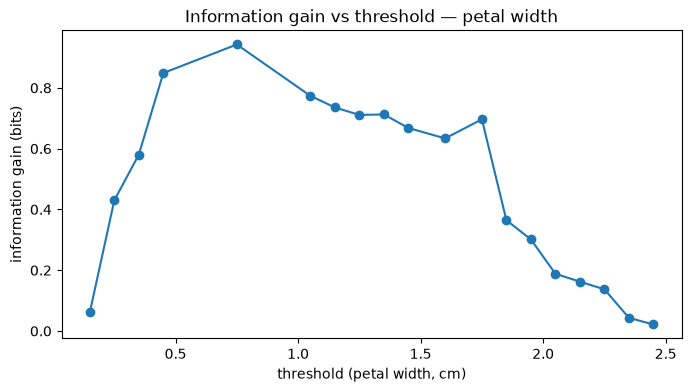

In [51]:
x = X_train["petal width"]  # EXTRACT PETAL WITH
v = np.sort(x.unique()) # extract values 
thresholds = (v[:-1] + v[1:]) / 2 # extract treshold and candidates
gains = [info_gain(x, y_train, t) for t in thresholds]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, gains, marker="o")
plt.xlabel("threshold (petal width, cm)")
plt.ylabel("information gain (bits)")
plt.title("Information gain vs threshold — petal width")
plt.show() # one elem and one side. entire entropy before splitting

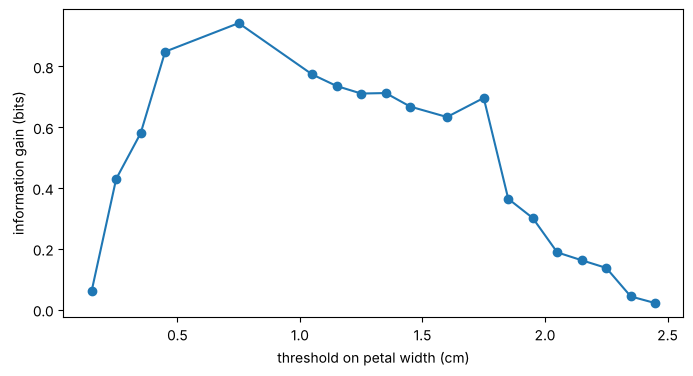

In [7]:
# your code here


**Answer.** *Write your answer here (double-click to edit).*

## A4. A fully grown tree on the original training set

1. Create a [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
   with `criterion="entropy"` (the default is Gini, Lecture 9) and `random_state=10`, and learn it with `fit` on the training set.
   Without other hyperparameters, the tree grows until its leaves are pure.
1. Draw it with `plot_tree(model, feature_names=..., class_names=..., filled=True)`.
1. Print its depth (`get_depth()`) and number of leaves (`get_n_leaves()`).

depth:  4 | leaves:  5


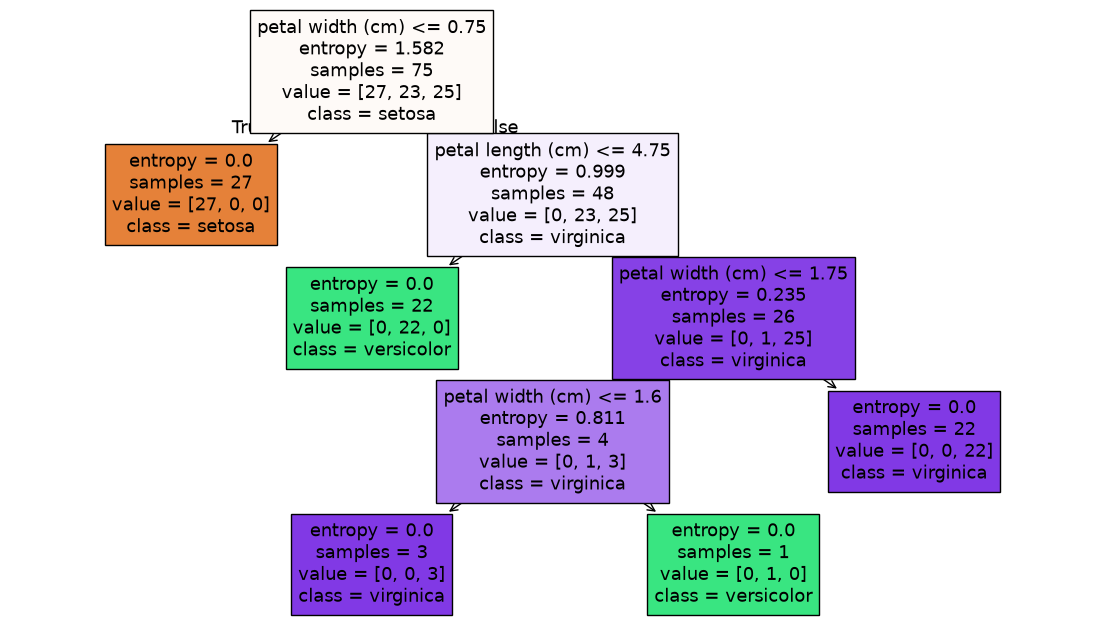

In [54]:
model = DecisionTreeClassifier(criterion="entropy", random_state=10)
model.fit(X_train, y_train)
print("depth: ", model.get_depth(), "| leaves: ", model.get_n_leaves())
plt.figure(figsize=(14, 8))
plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
)
plt.show()

depth: 4 | leaves: 5


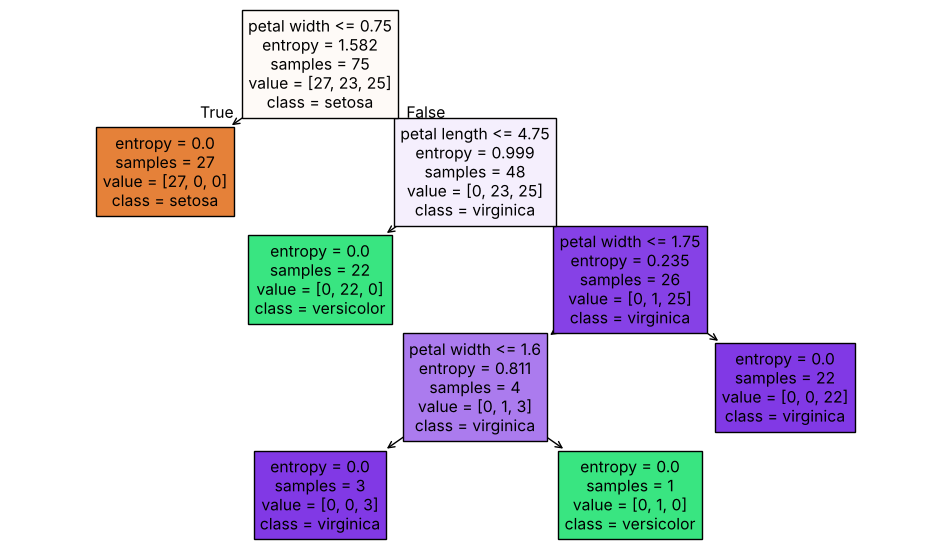

In [8]:
# your code here


### Training error and test error

Compute the predictions on the training set and on the test set, and for each one the **number of errors** and the **error rate**.

- `model.predict(X)` returns the predicted classes
- `(predicted != y).sum()` counts the errors; `accuracy_score(y, predicted)` gives the accuracy, and the error rate is 1 − accuracy
- `model.score(X, y)` computes the accuracy in one call

Since we will repeat this many times, write a small function `errors(model, X, y)` returning the number of errors.

In [9]:
# your code here


training errors:  0 / 75  (0.0%)   accuracy: 1.000
test     errors:  6 / 75  (8.0%)   accuracy: 0.920


**Answer.** *Write your answer here (double-click to edit).*

## A5. The altered training set of Lecture 9

To make noise and overfitting visible, Lecture 9 altered two training flowers:

- flower **125** (a virginica): label changed to 0 (setosa)
- flower **113** (a virginica): measurements overwritten with those of flower 125, label changed to 1 (versicolor)

1. Create the copies `X_train_alt` and `y_train_alt` (use `.copy()`: the original training set must stay untouched)
   and apply the two changes with `.loc[...]`: the numbers are row **labels** (the index of the original data set), not positions.
1. Check the class counts: Lecture 9 says 28/24/23.
1. Learn a fully grown tree `tree_alt` (same hyperparameters as before) on the altered set; draw it; count training and test errors.

In [10]:
# your code here


[28, 24, 23]
     sepal length  sepal width  petal length  petal width  label
113           7.2          3.2           6.0          1.8      1
125           7.2          3.2           6.0          1.8      0


depth: 5 | leaves: 6
training errors: 1 / 75
test errors:     12 / 75


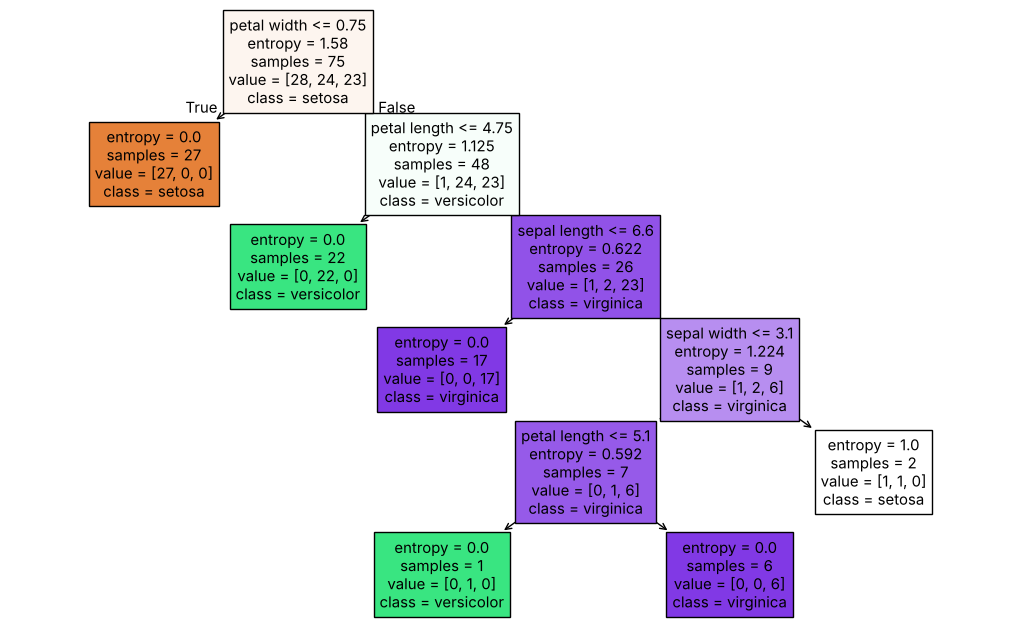

In [11]:
# your code here


### Inside the tree: the arrays of `tree_`

The learned tree is stored in the attribute `tree_` as parallel arrays, one position per node (Lecture 9, *internal representation*):
`children_left`, `children_right` (−1 for a leaf), `feature` (index of the tested column), `threshold`,
`n_node_samples`, `impurity`.

1. Put these arrays into a DataFrame, one row per node; replace the feature index with the column name, and show
   `-` for feature and threshold in the leaves.
1. Which leaf is impure? Which training flowers reach it? `model.apply(X)` returns, for every row, the node (leaf) where it ends.

In [12]:
# your code here


,left,right,feature,threshold,samples,entropy
0,1,2,petal width,0.75,75,1.580
1,-1,-1,-,-,27,0.000
2,3,4,petal length,4.75,48,1.125
3,-1,-1,-,-,22,0.000
4,5,6,sepal length,6.6,26,0.622
5,-1,-1,-,-,17,0.000
6,7,10,sepal width,3.1,9,1.224
7,8,9,petal length,5.1,7,0.592
8,-1,-1,-,-,1,0.000
9,-1,-1,-,-,6,0.000


In [13]:
# your code here


impure leaf: [10]
training flowers in it: [113, 125]


**Answer.** *Write your answer here (double-click to edit).*

## A6. Error vs depth: underfitting and overfitting

Learn trees on the **altered** training set with `max_depth` from 1 to 5. For each depth, record the training error rate
and the test error rate in a DataFrame, then plot the two curves (x: depth, y: error rate).
Compare with the figure *Errors and tree depth* of Lecture 9.

In [14]:
# your code here


,training error,test error
max_depth,,
1,32.0,33.3
2,4.0,8.0
3,4.0,8.0
4,2.7,17.3
5,1.3,16.0


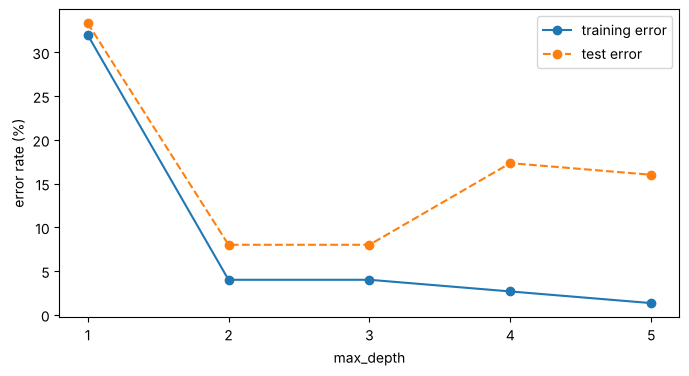

In [15]:
# your code here


**Question.** Where does the tree underfit, where does it overfit? Which depth would you choose?
And now the important question: **are you allowed to choose it this way?**

**Answer.** *Write your answer here (double-click to edit).*

## A7. Cross-validation, step by step

From now on the test set is **locked**. Everything happens on the 75 flowers of the (altered) training set.

### Step 1 — the folds

[`StratifiedKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)
cuts the training set into $k$ folds keeping the class proportions in each fold (*stratified*, Lecture 8).
Create `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)`.

`cv.split(X, y)` produces, for each round, two arrays of **positions**: the rows used to learn and the rows held out.
Loop over the rounds with `enumerate`, and for each one print the number of rows of the two parts and the class counts
of the held-out fold. Use `.iloc` to select rows by position.

In [1]:
# variation of IRIS ds -> 1 small error 
# classficatio of iris ds (3 class 4 feature)
# how can we do cross validation? Stratifykeyfold -> cuts tr set in 2 folds.
# subset -> same proportional of classes
# obj cv -> specify n° of split. random seed for replicability. shuffle true = before do the split, shuffle data 
# (if there dependences among other features and are hidden in the data set, we insert same randomness with spurious correlation)
# unless we are dealing with temporal data -> good habit to do shuffle (avoid spurious sorting)
# preserving proportion of class
# we can use method split -> use X e Y and execute split -> split not materially (no generation of different matrix) 
# but it will generate 5 set of indexes that index the record which is composed (position of the element that belong

# should train the classifiaer for each fold (loop run on the 5 folds)

# your code here
# split -> for generation -> 2 vectors of indexes (pos and held part which it will tested)
# held_count -> keep track of this splitting and print the situation
# count class in held-out (status or composition for each fold)

In [2]:
# your code here


**Question.** How many times is each flower held out? How many times is it used for learning?

**Answer.** *Write your answer here (double-click to edit).*

### Step 2 — one model per round, by hand

For a tree with `max_depth=2`: in each round learn a new tree on the learning part, compute its accuracy on the held-out fold,
and collect the five accuracies in a list. Print them, then their **mean** and **standard deviation**.

In [ ]:
# your code here
fold_acc # empty listy for accuracy in each fold
# extract all postion of learn and hold part (initialize a decision tree classifier) -> i fit on the folder that it is extract here

# fold_acc = computed with score method of fittyed model (takes the train e ground truth).
# list converted in array and see the result

# accuracy for each fold, mean and standard deviation


In [17]:
# your code here


[0.933 0.933 1.    1.    0.933]
mean 0.960, std 0.033


### Step 3 — the same in one line

[`cross_val_score(model, X, y, cv=cv)`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
does exactly the loop above and returns the five scores (accuracy, for a classifier). Check that you get the same numbers.

In [18]:
# your code here


# splitter alone -> it does exactly the loop sopra.

[0.933 0.933 1.    1.    0.933] | same as by hand: True


### Step 4 — choose the depth with cross-validation

For every `max_depth` from 1 to 5, compute mean and standard deviation of the 5-fold cross-validation accuracy
on the altered training set. Use **the same `cv` object** for all depths: same folds, fair comparison.
Collect the results in a DataFrame next to the test errors of A6 (which we computed, but **must not use** to choose).

In [ ]:
# call cross_val_scorwe with max_depth, append the result in a list of rows and at the end we create a dataframe to collect the result and prepare the final df.

# see all for each depth

In [19]:
# your code here


,CV accuracy mean,CV accuracy std,test accuracy (not to be used)
max_depth,,,
1,0.68,0.027,0.667
2,0.96,0.033,0.920
3,0.96,0.033,0.920
4,0.92,0.078,0.827
5,0.92,0.078,0.840


**Question.** Which depth does cross-validation choose? If two depths are equally good, which one do you prefer, and why?

**Answer.** *Write your answer here (double-click to edit).*

### Step 5 — the final model, and the one look at the test set

The chosen *way of building* the model is "tree with `max_depth=2`". Learn it on the **whole** training set
(not on one of the folds), and only now measure it, **once**, on the test set.

training errors: 3 / 75
test errors:     6 / 75 -> test accuracy 0.920


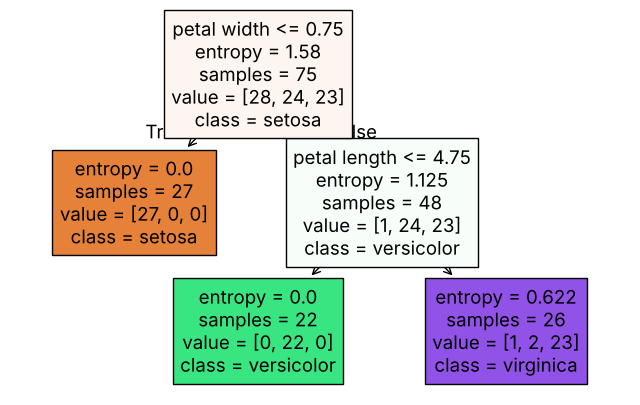

In [20]:
# your code here

# compute error on the test set -> for choosing the best maximum tree giving the best result, we never consider the test part.

**Answer.** *Write your answer here (double-click to edit).*

### Why shuffle and stratify? ★

Run `cross_val_score` of a fully grown tree on the **whole** Iris data set (`X`, `y`, which are sorted by class) with
`cv=KFold(3)` — no shuffling — and then with `cv=StratifiedKFold(3, shuffle=True, random_state=SEED)`. Explain the difference.

In [21]:
# your code here


KFold(3), no shuffle:       [0. 0. 0.]
StratifiedKFold(3), shuffle: [1.   0.94 0.94]


**Answer.** *Write your answer here (double-click to edit).*

### A cross-validation estimate also varies ★

Repeat Step 4 for depth 2 and depth 4 with five different `random_state` values of `StratifiedKFold` (e.g. 0 to 4).
How much does the mean change? What does it tell you about comparing two depths whose CV means differ by 0.01?

In [22]:
# your code here


depth 2: [0.96  0.96  0.96  0.96  0.933]


depth 4: [0.933 0.947 0.96  0.947 0.92 ]


**Answer.** *Write your answer here (double-click to edit).*

# Part B — NordicMart: a churn tree

The customer table of Lecture 6 and Lab 1: 3000 customers, target `churned` (12% churners).
The setup is the same as Lecture 10, so your numbers will appear on Wednesday's slides.

## B1. Features, target, baseline

1. Load the file into `df` (raw table, not modified).
1. Features: `tier`, `age`, `days_since_last_buy`, `annual_spend`, `web_sessions_month`, `tickets_90d`.
   `customer_id` is an identifier, `postcode` is constant (Lab 1): neither is a feature. Target: `churned`.
1. scikit-learn trees need numeric features: code `tier`, which is ordinal, as Basic = 0, Silver = 1, Gold = 2 with
   `.map({...})`. The general treatment of categorical attributes comes in session 16.
1. Missing values stay `NaN`: the tree handles them (see B6). Count them per column.
1. Baseline accuracy?

In [23]:
# your code here


(3000, 6)
tier                     0
age                    303
days_since_last_buy      0
annual_spend             0
web_sessions_month     540
tickets_90d              0
dtype: int64
baseline accuracy ('nobody churns'): 88.0%


## B2. A stratified train/test split

With an imbalanced target a plain random split can, by chance, put a different share of churners in the two parts.
Split 70/30 with `test_size=0.3`, `stratify=yn` and `random_state=SEED`, and check size and churn rate of the two parts.

In [24]:
# your code here


,customers,churners,churn rate
training,2100,252,0.12
test,900,108,0.12


## B3. A fully grown tree

Learn a `DecisionTreeClassifier(random_state=0)` (default criterion: Gini) on the training part.
Print depth and number of leaves, training and test accuracy, and compare with the baseline.
Then show the cross-table of actual vs predicted classes on the test set (`pd.crosstab`, as in Lab 1).

In [25]:
# your code here


depth: 23 | leaves: 289
training accuracy 1.000 | test accuracy 0.824 | baseline 0.880


predicted,0,1
actual,,
0,705,87
1,71,37


**Answer.** *Write your answer here (double-click to edit).*

## B4. Choosing the depth with cross-validation

Use [`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html):
like `cross_val_score`, but it returns a dictionary and, with `return_train_score=True`, also the accuracy
on the learning part of each round (`"train_score"`) besides the held-out one (`"test_score"`).

1. Create `cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)` (the folds of Lecture 10).
1. For `max_depth` in `[1, 2, 3, 4, 5, 6, 8, 10, 12, None]` record: mean training accuracy, mean and std of the held-out accuracy.
1. Plot the two curves; draw the held-out one with error bars (`ax.errorbar(..., yerr=std)`) and the baseline as a horizontal line.

In [26]:
# your code here


,training,held-out mean,held-out std
max_depth,,,
1,0.881,0.879,0.004
2,0.895,0.887,0.008
3,0.899,0.888,0.008
4,0.906,0.890,0.006
5,0.915,0.886,0.010
6,0.926,0.879,0.013
8,0.944,0.880,0.009
10,0.964,0.863,0.015
12,0.979,0.854,0.017


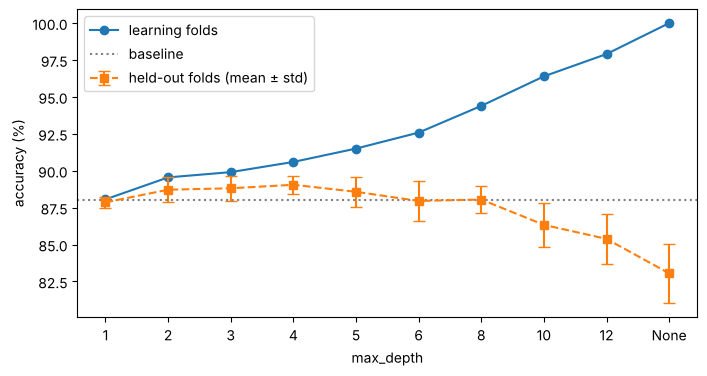

In [27]:
# your code here


**Question.** Which depth does cross-validation choose? How far is it from the baseline? How large is the standard deviation
compared with the differences between depths 2 and 5?

**Answer.** *Write your answer here (double-click to edit).*

## B5. Another hyperparameter: `min_samples_leaf` ★

Keep `max_depth=4` and try `min_samples_leaf` in `[1, 10, 30, 100]` (the minimum number of training customers in a leaf,
one of the meanings of "the data set is small" in Lecture 9). Use the same `cv_n`.

In [28]:
# your code here


min_samples_leaf=  1: 0.8905 ± 0.0062
min_samples_leaf= 10: 0.8876 ± 0.0079
min_samples_leaf= 30: 0.8876 ± 0.0079
min_samples_leaf=100: 0.8819 ± 0.0097


**Answer.** *Write your answer here (double-click to edit).*

## B6. The final model: one test measure, and reading the tree

1. Learn the tree with the chosen depth on the **whole** training part; compute the test accuracy and the cross-table, **once**.
1. Print the first two levels of the tree as text with `export_text(model, feature_names=FEATURES, max_depth=2)`.

In [29]:
# your code here


test accuracy 0.879 | baseline 0.880


predicted,0,1
actual,,
0,768,24
1,85,23


In [30]:
# your code here


|--- days_since_last_buy <= 111.50
|   |--- web_sessions_month <= inf
|   |   |--- annual_spend <= 5778.30
|   |   |   |--- truncated branch of depth 2
|   |   |--- annual_spend >  5778.30
|   |   |   |--- class: 1
|   |--- web_sessions_month >  inf
|   |   |--- days_since_last_buy <= 52.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- days_since_last_buy >  52.50
|   |   |   |--- truncated branch of depth 2
|--- days_since_last_buy >  111.50
|   |--- web_sessions_month <= 0.50
|   |   |--- age <= 59.00
|   |   |   |--- truncated branch of depth 2
|   |   |--- age >  59.00
|   |   |   |--- truncated branch of depth 2
|   |--- web_sessions_month >  0.50
|   |   |--- days_since_last_buy <= 733.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- days_since_last_buy >  733.50
|   |   |   |--- truncated branch of depth 2



**Questions.**

1. Test accuracy vs CV estimate vs baseline: what do you conclude? How many churners does the tree find?
1. Which attribute is at the root? Does it agree with what EDA suggested in Lab 1?
1. Two tests look strange: `web_sessions_month <= inf` and `days_since_last_buy > 733.50`. What are they doing?
   (Hint: what is in Lab 1's EDA log about missing sessions and the value 999?)

**Answer.** *Write your answer here (double-click to edit).*

## B7. Data leakage: a tree that is too good

Lecture 9, *Route 2*: suppose that somebody added the column `days_since_last_buy_today`, recency measured **today**,
90 days after the snapshot. By definition a churner bought nothing in those 90 days, so for churners this value is
the old recency + 90; for the others it is below 90.

The cell below creates this column in a copy of the features (it simulates the error; do not change it).
Then: repeat the split of B2 on `Xleak`, compute the 5-fold CV accuracy of a depth-4 tree, and print the attribute and threshold of its root
(`model.tree_.feature[0]`, `model.tree_.threshold[0]`).

In [31]:
rng = np.random.default_rng(SEED)
Xleak = Xn.copy()
Xleak["days_since_last_buy_today"] = np.where(yn == 1, Xn["days_since_last_buy"] + 90, rng.integers(1, 91, len(Xn)))

In [32]:
# your code here


CV accuracy 1.000 ± 0.000
root: days_since_last_buy_today <= 90.5


**Answer.** *Write your answer here (double-click to edit).*

## B8. The Lab 1 recodings ★

In Lab 1 we recoded 999 and `age == 0` as missing, with a flag `never_bought`. Apply the same recodings to a copy of
`Xn_train` and compare the CV accuracy at depths 3, 4, 5 with the unrecoded features.

**Question.** These recodings are applied before cross-validation, to all rows: is it a leakage like *Route 1* of Lecture 9?

In [33]:
# your code here


depth 3: raw 0.8881 | recoded 0.8948


depth 4: raw 0.8905 | recoded 0.8919


depth 5: raw 0.8857 | recoded 0.8914


**Answer.** *Write your answer here (double-click to edit).*

## Experiment log

Complete the log (double-click to edit). One row per model you would report; the test column is filled only for the final models.

| Data | Model | How chosen | CV accuracy | Test accuracy |
|---|---|---|---|---|
| *Iris, altered* | *majority class* | *—* | *—* | *33%* |
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the raw training set of Iris was not modified by the alterations, and that the final models were measured on the test set only once.

In [34]:
# quick self-check
assert y_train.loc[125] == 2 and y_train.loc[113] == 2, "the original Iris training set was modified!"
assert errors(tree_orig, X_train, y_train) == 0
print("original training set untouched")

original training set untouched
